---

# Tugas Besar 2 IF3170 Inteligensi Artifisial

*Prediksi pembatalan pemesanan penginapan dengan lima model, submisi final KNN from scratch.*

---

## Kelompok 17 DerbyCounty

- NIM - Nama
- NIM - Nama
- NIM - Nama
- NIM - Nama
- 13524093 - Reinsen Silitonga

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Exploratory Data Analysis**](#3)
4. [**Data Cleaning and Preprocessing**](#4)
5. [**Modeling and Validation**](#5)
6. [**Error Analysis**](#6)
7. [**Submission**](#7)

---

# Introduction <a name="1"></a>

---

*Cristiano Ronaldo sedang membangun Ronaldo Hotel dan ingin tahu lebih awal tamu mana yang kemungkinan membatalkan pesanannya. Prediksi ini membantu penginapan merencanakan overbooking, mengirim pengingat, dan menyusun kebijakan pembatalan.*

Notebook ini membandingkan lima model (KNN, Decision Tree, SVM, Logistic Regression, Gaussian Naive Bayes) dengan metrik macro F1-score. KNN dan Decision Tree memakai implementasi from scratch kelompok. SVM, Logistic Regression, dan Gaussian NB memakai scikit-learn sebagai pembanding. Submisi final memakai KNN from scratch, model dengan skor public terbaik (0,85505).

---

# Initialization <a name="2"></a>

---

Persiapan pustaka, pengaturan, dan dataset.

## Environment Setup

Seluruh library yang dipakai notebook ini. Jalankan sekali jika belum terpasang.

In [1]:
# %pip install matplotlib numpy pandas scikit-learn

## Import Libraries

Seluruh import dikumpulkan pada satu sel.

In [ ]:
import copy
import math
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import ParameterGrid, StratifiedKFold, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

## Kode Pendukung

Fungsi preprocessing bersama kelompok: konstanta kolom, `clean_train` (buang duplikat persis), `mark_invalid` (num_adults 0 menjadi missing), dan `add_features` (fitur turunan per baris).

In [ ]:
# Preprocessing bersama untuk semua model: konstanta, cleaning, fitur turunan, dan BasePreprocessor.


TARGET = 'is_canceled'
ID_COL = 'id'
CAT_COLS = ['meal_package', 'room_category', 'booking_channel']


# Buang baris duplikat persis (fitur dan target). Hanya untuk data train.
def clean_train(df):
    feature_cols = [c for c in df.columns if c != ID_COL]
    return df.drop_duplicates(subset=feature_cols).reset_index(drop=True)


# Ubah nilai yang tidak masuk akal (num_adults = 0) menjadi missing.
def mark_invalid(df):
    df = df.copy()
    df.loc[df['num_adults'] == 0, 'num_adults'] = np.nan
    return df


# Tambah fitur turunan per baris, aman dipakai pada train dan test secara terpisah.
def add_features(df):
    df = df.copy()
    df['total_nights'] = df['weekend_nights'] + df['weekday_nights']
    df['total_guests'] = df['num_adults'] + df['num_children']
    df['is_free'] = (df['nightly_rate_idr'] == 0).astype(float)
    df.loc[df['nightly_rate_idr'].isna(), 'is_free'] = np.nan
    df['rate_per_guest'] = df['nightly_rate_idr'] / df['total_guests'].replace(0, np.nan)

    arrival = pd.to_datetime(
        dict(year=df['arrival_year'], month=df['arrival_month'], day=df['arrival_day']),
        errors='coerce',
    )
    df['arrival_weekday'] = arrival.dt.weekday.astype(float)
    df['arrival_dayofyear'] = arrival.dt.dayofyear.astype(float)
    df['arrival_index'] = ((arrival - pd.Timestamp('2023-01-01')).dt.days).astype(float)
    return df

Decision Tree from scratch kelompok. Mendukung kriteria `gini`, `entropy`, dan `gain_ratio` (C4.5), atribut numerik dan kategorikal, serta missing value.

In [ ]:
# Implementasi Decision Tree Learning (CART) from scratch untuk klasifikasi biner.




# Satu node pohon. Daun hanya memakai value (proporsi kelas 1) dan n_samples.
class Node:
    __slots__ = ('feature', 'threshold', 'is_cat', 'left_cats', 'seen_cats',
                 'missing_left', 'frac_left', 'left', 'right', 'value', 'n_samples', 'n_pos', 'gain')

    # Buat node dengan proporsi kelas 1 dan jumlah sampelnya.
    def __init__(self, value, n_samples):
        self.value = value
        self.n_samples = n_samples
        self.n_pos = None
        self.feature = None
        self.threshold = None
        self.is_cat = False
        self.left_cats = None
        self.seen_cats = None
        self.missing_left = True
        self.frac_left = None
        self.left = None
        self.right = None
        self.gain = 0.0

    # True jika node tidak punya anak.
    @property
    def is_leaf(self):
        return self.left is None


# Impurity gini atau entropy secara vektor dari jumlah positif dan total sampel.
def _impurity(pos, n, criterion):
    n = np.asarray(n, dtype=float)
    p = np.divide(pos, n, out=np.zeros_like(n), where=n > 0)
    if criterion == 'gini':
        return 2.0 * p * (1.0 - p)
    # Entropy biner, dengan konvensi 0 * log(0) = 0
    q = 1.0 - p
    with np.errstate(divide='ignore', invalid='ignore'):
        h = -(np.where(p > 0, p * np.log2(p), 0.0) + np.where(q > 0, q * np.log2(q), 0.0))
    return h


# P-value uji chi-square (df = 1) untuk tabel 2x2 cabang kiri/kanan x kelas 0/1.
def _chi2_p_value(nl, pl, nr, pr):
    n, pos = nl + nr, pl + pr
    denom = nl * nr * pos * (n - pos)
    if denom == 0:
        return 1.0
    chi2 = n * (pl * (nr - pr) - pr * (nl - pl)) ** 2 / denom
    # Distribusi chi-square df 1: P(X > x) = erfc(sqrt(x / 2))
    return math.erfc(math.sqrt(chi2 / 2.0))


# Nilai dengan total bobot terbesar (nilai paling umum).
def _weighted_mode(x, w):
    vals, inv = np.unique(x, return_inverse=True)
    return vals[int(np.argmax(np.bincount(inv, weights=w)))]


# CART biner: split numerik dengan threshold, kategori diurutkan berdasarkan proporsi kelas 1,
# missing value ditangani sesuai parameter missing (default: ke cabang dengan impurity terkecil).
class DecisionTree:
    # criterion: 'gini', 'entropy', atau 'gain_ratio' (C4.5).
    # min_impurity_decrease: penurunan impurity terbobot minimum agar split diterima.
    # max_p_value: jika diisi, split hanya dibuat jika p-value uji chi-square <= nilai ini.
    # missing: cara menangani missing value saat split.
    #   'default'         : missing ke cabang dengan impurity terkecil
    #   'node_mode'       : missing diberi nilai paling umum di simpul
    #   'node_mode_class' : saat training, nilai paling umum di simpul pada kelas yang sama;
    #                       saat prediksi kelas belum diketahui, jadi memakai nilai paling umum di simpul
    #   'fractional'      : C4.5, gain dikali proporsi data yang diketahui dan missing dibagi
    #                       ke kedua cabang dengan bobot pecahan
    # class_weight: None, 'balanced', atau angka bobot kelas 1 relatif terhadap kelas 0.
    # m_estimate: smoothing probabilitas daun, (pos + m * prior) / (n + m); 0 berarti tanpa smoothing.
    # ccp_alpha: jika > 0, pohon dipangkas dengan cost-complexity pruning setelah dibangun.
    def __init__(self, criterion='gini', max_depth=None, min_samples_split=2,
                 min_samples_leaf=1, min_impurity_decrease=0.0, max_p_value=None,
                 missing='default', class_weight=None, m_estimate=0.0, ccp_alpha=0.0):
        self.criterion = criterion
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.min_impurity_decrease = min_impurity_decrease
        self.max_p_value = max_p_value
        self.missing = missing
        self.class_weight = class_weight
        self.m_estimate = m_estimate
        self.ccp_alpha = ccp_alpha

    # ------------------------------------------------------------ training

    # Latih pohon. Kolom bertipe teks pada X dianggap kategorikal.
    def fit(self, X, y):
        X = pd.DataFrame(X)
        self.feature_names_ = list(X.columns)
        self.is_cat_ = np.array([not pd.api.types.is_numeric_dtype(X[c]) for c in X.columns])
        # Kamus kategori ke kode integer, dipelajari dari data train
        self.cat_maps_ = {}
        for j, c in enumerate(self.feature_names_):
            if self.is_cat_[j]:
                cats = sorted(X[c].dropna().unique())
                self.cat_maps_[c] = {v: i for i, v in enumerate(cats)}

        self._X = self._to_array(X)
        self._y = np.asarray(y).astype(int)
        self.n_total_ = len(self._y)
        self.feature_importances_ = np.zeros(len(self.feature_names_))

        # Bobot awal per baris: semua 1, atau bobot kelas yang dinormalisasi agar totalnya tetap n
        w = np.ones(self.n_total_)
        if self.class_weight is not None:
            n_pos = self._y.sum()
            w1 = ((self.n_total_ - n_pos) / n_pos if self.class_weight == 'balanced'
                  else float(self.class_weight))
            w[self._y == 1] = w1
            w *= self.n_total_ / w.sum()
        self.prior_ = float(w @ self._y) / self.n_total_

        self.root_ = self._build(np.arange(self.n_total_), w, depth=0)

        total = self.feature_importances_.sum()
        if total > 0:
            self.feature_importances_ /= total
        del self._X, self._y
        if self.ccp_alpha > 0:
            self.cost_complexity_prune(self.ccp_alpha)
        return self

    # Ubah DataFrame jadi array float: kategori jadi kode, missing jadi NaN, kategori baru jadi -2.
    def _to_array(self, X):
        out = np.empty((len(X), len(self.feature_names_)), dtype=float)
        for j, c in enumerate(self.feature_names_):
            if self.is_cat_[j]:
                # Kategori yang tidak dikenal saat train diberi kode -2
                codes = X[c].map(self.cat_maps_[c])
                codes = codes.where(X[c].isna() | codes.notna(), -2)
                out[:, j] = codes.astype(float).to_numpy()
            else:
                out[:, j] = pd.to_numeric(X[c], errors='coerce').to_numpy(dtype=float)
        return out

    # Bangun pohon secara rekursif dari indeks baris idx dengan bobot w (semua 1 kecuali 'fractional').
    def _build(self, idx, w, depth):
        y = self._y[idx]
        n, pos = float(w.sum()), float(w @ y)
        m = getattr(self, 'm_estimate', 0.0)
        value = pos / n if m == 0 else (pos + m * self.prior_) / (n + m)
        node = Node(value=value, n_samples=int(n) if n == int(n) else n)
        node.n_pos = pos

        # Kondisi berhenti (pre-pruning)
        if (pos == 0 or pos == n
                or n < self.min_samples_split
                or n < 2 * self.min_samples_leaf
                or (self.max_depth is not None and depth >= self.max_depth)):
            return node

        best = self._best_split(idx, y, w)
        if best is None:
            return node

        gain, f, thr, left_cats, seen_cats, miss_left, miss_by_class = best
        # Penurunan impurity dibobot proporsi sampel node terhadap seluruh data
        weighted_gain = gain * n / self.n_total_
        if weighted_gain < self.min_impurity_decrease:
            return node

        x, is_cat = self._X[idx, f], self.is_cat_[f]
        frac_left = None
        if self.missing == 'fractional':
            # Baris yang diketahui ikut kondisi split, baris missing masuk ke kedua cabang
            unknown = np.isnan(x)
            known_left = ~unknown & self._cond(x, thr, left_cats, is_cat)
            frac_left = float(w[known_left].sum() / w[~unknown].sum())
            left_mask, right_mask = known_left | unknown, (~unknown & ~known_left) | unknown
            w_left = np.where(unknown, w * frac_left, w)[left_mask]
            w_right = np.where(unknown, w * (1.0 - frac_left), w)[right_mask]
        else:
            go_left = self._go_left(x, thr, left_cats, seen_cats, miss_left, is_cat)
            if miss_by_class is not None:
                # Saat training, missing diarahkan sesuai nilai paling umum pada kelasnya
                go_left = np.where(np.isnan(x), np.where(y == 1, miss_by_class[1], miss_by_class[0]),
                                   go_left)
            left_mask, right_mask = go_left, ~go_left
            w_left, w_right = w[go_left], w[~go_left]

        if self.max_p_value is not None:
            nl, pl = float(w_left.sum()), float(w_left @ y[left_mask])
            if _chi2_p_value(nl, pl, n - nl, pos - pl) > self.max_p_value:
                return node
        node.feature, node.threshold = f, thr
        node.is_cat = bool(is_cat)
        node.left_cats, node.seen_cats = left_cats, seen_cats
        node.missing_left = miss_left
        node.frac_left = frac_left
        node.gain = gain
        self.feature_importances_[f] += weighted_gain

        node.left = self._build(idx[left_mask], w_left, depth + 1)
        node.right = self._build(idx[right_mask], w_right, depth + 1)
        return node

    # Cari split terbaik dari semua fitur, None jika tidak ada split valid.
    def _best_split(self, idx, y, w):
        n = float(w.sum())
        wy = w * y
        parent = _impurity(wy.sum(), n, self.criterion)
        best_gain, best = 1e-12, None
        candidates = []

        for f in range(self._X.shape[1]):
            x = self._X[idx, f]
            miss = np.isnan(x)
            w_miss, pos_miss = float(w[miss].sum()), float(wy[miss].sum())
            xv, yv, wv = x[~miss], y[~miss], w[~miss]
            if len(xv) < 2:
                continue

            if self.is_cat_[f]:
                # Urutkan kategori berdasarkan proporsi positif, lalu ganti nilai x dengan peringkatnya
                cats, inv = np.unique(xv, return_inverse=True)
                if len(cats) < 2:
                    continue
                cnt = np.bincount(inv, weights=wv)
                pos_rate = np.bincount(inv, weights=wv * yv) / cnt
                order = np.argsort(pos_rate, kind='mergesort')
                rank = np.empty(len(cats), dtype=int)
                rank[order] = np.arange(len(cats))
                xv = rank[inv].astype(float)

            sort = np.argsort(xv, kind='mergesort')
            xs, ys, ws = xv[sort], yv[sort], wv[sort]
            # Kandidat titik potong: hanya di antara dua nilai yang berbeda
            cut = np.where(xs[:-1] != xs[1:])[0]
            if len(cut) == 0:
                continue
            cum_w = np.cumsum(ws)
            cum_pos = np.cumsum(ws * ys)
            n_left = cum_w[cut]
            p_left = cum_pos[cut]
            w_known, pos_known = cum_w[-1], cum_pos[-1]

            # Tiap opsi: (missing kelas 0 ke kiri, missing kelas 1 ke kiri, arah missing saat prediksi)
            if self.missing == 'fractional':
                options = [None]
            elif self.missing in ('node_mode', 'node_mode_class'):
                mode_left = xs[cut] >= _weighted_mode(xs, ws)
                if self.missing == 'node_mode':
                    options = [(mode_left, mode_left, mode_left)]
                else:
                    # Kelas yang tidak punya data diketahui memakai nilai paling umum di simpul
                    by_class = []
                    for c in (0, 1):
                        m = ys == c
                        by_class.append(xs[cut] >= _weighted_mode(xs[m], ws[m]) if m.any() else mode_left)
                    options = [(by_class[0], by_class[1], mode_left)]
            else:
                options = [(True, True, True), (False, False, False)] if w_miss > 0 else [(True, True, True)]

            for opt in options:
                if opt is None:
                    # C4.5: gain dihitung dari data yang diketahui lalu dikali proporsinya
                    nl, pl = n_left, p_left
                    nr, pr = w_known - n_left, pos_known - p_left
                    valid = (nl >= self.min_samples_leaf) & (nr >= self.min_samples_leaf)
                    if not valid.any():
                        continue
                    child = (nl * _impurity(pl, nl, self.criterion)
                             + nr * _impurity(pr, nr, self.criterion)) / w_known
                    known_parent = _impurity(pos_known, w_known, self.criterion)
                    gain = np.where(valid, (w_known / n) * (known_parent - child), -np.inf)
                    split_total = w_known
                    miss_pred = True
                else:
                    ml0, ml1, miss_pred = opt
                    nl = n_left + ml0 * (w_miss - pos_miss) + ml1 * pos_miss
                    pl = p_left + ml1 * pos_miss
                    nr = (w_known + w_miss) - nl
                    pr = (pos_known + pos_miss) - pl
                    valid = (nl >= self.min_samples_leaf) & (nr >= self.min_samples_leaf)
                    if not valid.any():
                        continue
                    child = (nl * _impurity(pl, nl, self.criterion)
                             + nr * _impurity(pr, nr, self.criterion)) / n
                    gain = np.where(valid, parent - child, -np.inf)
                    split_total = n

                # Hasil split untuk titik potong ke-i
                def make_split(i, g):
                    pick = lambda v: bool(v[i]) if isinstance(v, np.ndarray) else bool(v)
                    miss_left = pick(miss_pred)
                    by_class = ((pick(opt[0]), pick(opt[1])) if self.missing == 'node_mode_class'
                                and opt is not None else None)
                    if self.is_cat_[f]:
                        # Kategori dengan peringkat <= titik potong masuk ke kiri
                        left_cats = cats[order[: int(xs[cut[i]]) + 1]]
                        return (g, f, None, left_cats, cats, miss_left, by_class)
                    thr = (xs[cut[i]] + xs[cut[i] + 1]) / 2.0
                    return (g, f, thr, None, None, miss_left, by_class)

                if self.criterion == 'gain_ratio':
                    # C4.5: gain ratio hanya untuk titik potong dengan gain >= rata-rata gain
                    ok = gain > 1e-12
                    if not ok.any():
                        continue
                    ok &= gain >= gain[ok].mean() - 1e-12
                    split_info = _impurity(nl, np.full_like(nl, split_total), 'entropy')
                    ratio = np.where(ok, gain / np.maximum(split_info, 1e-12), -np.inf)
                    i = int(np.argmax(ratio))
                    candidates.append((float(ratio[i]), make_split(i, float(gain[i]))))
                    continue

                i = int(np.argmax(gain))
                if gain[i] > best_gain:
                    best_gain = float(gain[i])
                    best = make_split(i, best_gain)

        if self.criterion == 'gain_ratio' and candidates:
            # Antar atribut: pilih gain ratio terbesar dari atribut dengan gain >= rata-rata
            avg_gain = np.mean([s[0] for _, s in candidates])
            ratio, best = max((c for c in candidates if c[1][0] >= avg_gain - 1e-12), key=lambda c: c[0])
        return best

    # Tentukan baris yang masuk cabang kiri. Missing dan kategori tak dikenal ikut arah default.
    @staticmethod
    def _go_left(x, thr, left_cats, seen_cats, miss_left, is_cat):
        if is_cat:
            # Missing dan kategori yang tidak pernah terlihat di node ini ikut arah default
            unknown = np.isnan(x) | ~np.isin(x, seen_cats)
            return np.where(unknown, miss_left, np.isin(x, left_cats))
        return np.where(np.isnan(x), miss_left, x <= thr)

    # Kondisi split untuk nilai yang diketahui, True berarti masuk cabang kiri.
    @staticmethod
    def _cond(x, thr, left_cats, is_cat):
        if is_cat:
            return np.isin(x, left_cats)
        with np.errstate(invalid='ignore'):
            return x <= thr

    # ------------------------------------------------------------ pruning

    # Reduced-error pruning dari bawah ke atas: subtree diganti daun jika error validasi tidak naik.
    # Label daun memakai threshold (default 0.5 = kelas mayoritas).
    def prune(self, X_val, y_val, threshold=0.5):
        if getattr(self, 'missing', 'default') == 'fractional':
            raise NotImplementedError('prune belum mendukung missing fractional')
        Xa = self._to_array(pd.DataFrame(X_val))
        yv = np.asarray(y_val).astype(int)

        # Kembalikan jumlah error validasi pada subtree node setelah anak-anaknya dipangkas.
        def visit(node, idx):
            leaf_err = int(np.sum(yv[idx] != int(node.value >= threshold)))
            if node.is_leaf:
                return leaf_err
            go_left = self._go_left(Xa[idx, node.feature], node.threshold, node.left_cats,
                                    node.seen_cats, node.missing_left, node.is_cat)
            sub_err = visit(node.left, idx[go_left]) + visit(node.right, idx[~go_left])
            if leaf_err <= sub_err:
                node.left = node.right = None
                node.feature = None
                return leaf_err
            return sub_err

        visit(self.root_, np.arange(len(yv)))
        self._recompute_importances()
        return self

    # Cost-complexity pruning (CART): untuk alpha tertentu, cari subtree dengan
    # R(T) + alpha * |daun| terkecil. R dihitung dari impurity daun yang dibobot proporsi sampel.
    def cost_complexity_prune(self, alpha):
        crit = 'gini' if self.criterion == 'gini' else 'entropy'

        # Kembalikan (R subtree terbaik, jumlah daun) setelah anak-anaknya dipangkas.
        def visit(node):
            r_leaf = node.n_samples / self.n_total_ * float(
                _impurity(node.n_pos, node.n_samples, crit))
            if node.is_leaf:
                return r_leaf, 1
            r_left, n_left = visit(node.left)
            r_right, n_right = visit(node.right)
            r_sub, n_sub = r_left + r_right, n_left + n_right
            if r_leaf + alpha <= r_sub + alpha * n_sub:
                node.left = node.right = None
                node.feature = None
                return r_leaf, 1
            return r_sub, n_sub

        visit(self.root_)
        self._recompute_importances()
        return self

    # Hitung ulang feature importance dari split yang masih tersisa.
    def _recompute_importances(self):
        imp = np.zeros(len(self.feature_names_))
        stack = [self.root_]
        while stack:
            node = stack.pop()
            if node.is_leaf:
                continue
            imp[node.feature] += node.gain * node.n_samples / self.n_total_
            stack += [node.left, node.right]
        total = imp.sum()
        self.feature_importances_ = imp / total if total > 0 else imp

    # ------------------------------------------------------------ prediksi

    # Probabilitas kelas 1 (proporsi kelas 1 di daun) untuk tiap baris.
    def predict_proba(self, X):
        Xa = self._to_array(pd.DataFrame(X))
        if getattr(self, 'missing', 'default') == 'fractional':
            return self._predict_fractional(Xa)
        out = np.empty(len(Xa))
        stack = [(self.root_, np.arange(len(Xa)))]
        while stack:
            node, idx = stack.pop()
            if node.is_leaf or len(idx) == 0:
                out[idx] = node.value
                continue
            go_left = self._go_left(Xa[idx, node.feature], node.threshold, node.left_cats,
                                    node.seen_cats, node.missing_left, node.is_cat)
            stack.append((node.left, idx[go_left]))
            stack.append((node.right, idx[~go_left]))
        return out

    # Prediksi C4.5: baris yang missing di simpul diteruskan ke kedua cabang dengan bobot frac_left,
    # hasilnya rata-rata terbobot dari daun yang dicapai.
    def _predict_fractional(self, Xa):
        out = np.zeros(len(Xa))
        stack = [(self.root_, np.arange(len(Xa)), np.ones(len(Xa)))]
        while stack:
            node, idx, w = stack.pop()
            if len(idx) == 0:
                continue
            if node.is_leaf:
                out[idx] += w * node.value
                continue
            x = Xa[idx, node.feature]
            # Missing dan kategori yang tidak pernah terlihat di simpul ini dianggap tidak diketahui
            unknown = np.isnan(x) | (~np.isin(x, node.seen_cats) if node.is_cat else False)
            left = ~unknown & self._cond(x, node.threshold, node.left_cats, node.is_cat)
            right = ~unknown & ~left
            stack.append((node.left, np.concatenate([idx[left], idx[unknown]]),
                          np.concatenate([w[left], w[unknown] * node.frac_left])))
            stack.append((node.right, np.concatenate([idx[right], idx[unknown]]),
                          np.concatenate([w[right], w[unknown] * (1.0 - node.frac_left)])))
        return out

    # Label 0/1 berdasarkan threshold.
    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

    # ------------------------------------------------------------ inspeksi

    # Kedalaman pohon hasil training.
    def get_depth(self):
        def depth(node):
            return 0 if node.is_leaf else 1 + max(depth(node.left), depth(node.right))
        return depth(self.root_)

    # Jumlah daun pohon.
    def get_n_leaves(self):
        def leaves(node):
            return 1 if node.is_leaf else leaves(node.left) + leaves(node.right)
        return leaves(self.root_)

    # Teks kondisi split sebuah node, misalnya 'days_before_arrival <= 150.5'.
    def describe_split(self, node):
        name = self.feature_names_[node.feature]
        if node.is_cat:
            inv = {v: k for k, v in self.cat_maps_[name].items()}
            cats = ', '.join(str(inv[int(c)]) for c in node.left_cats)
            return f'{name} in {{{cats}}}'
        return f'{name} <= {node.threshold:.4g}'

## Settings

Path, seed, dan pengaturan validasi berada pada `Settings`.

In [ ]:
class Settings:
    SEED = 42
    ID_COLUMN = 'id'
    TARGET = 'is_canceled'
    TEST_SIZE = 0.2
    N_FOLDS = 5
    SUB_PATH = 'submission.csv'

random.seed(Settings.SEED)
np.random.seed(Settings.SEED)

## Load Dataset

Isi variabel `train` (dengan kolom `is_canceled`) dan `test` sebagai DataFrame pada sel berikut. Kolom `id` dibaca sebagai teks.

In [ ]:
train = pd.read_csv('train.csv', dtype={'id': str})
test = pd.read_csv('test.csv', dtype={'id': str})

pd.Series({'train': len(train), 'test': len(test)})

---

# Exploratory Data Analysis <a name="3"></a>

---

Pemeriksaan data sebelum pemodelan.

## Data Overview

Gambaran awal `train` dan `test`.

In [5]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 27373 entries, 0 to 27372
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id                        27373 non-null  str    
 1   num_adults                26564 non-null  float64
 2   num_children              24338 non-null  float64
 3   weekend_nights            27373 non-null  int64  
 4   weekday_nights            27373 non-null  int64  
 5   meal_package              25613 non-null  str    
 6   needs_parking             26291 non-null  float64
 7   room_category             26371 non-null  str    
 8   days_before_arrival       26250 non-null  float64
 9   arrival_year              27373 non-null  int64  
 10  arrival_month             27373 non-null  int64  
 11  arrival_day               27373 non-null  int64  
 12  booking_channel           27373 non-null  str    
 13  is_returning_guest        27373 non-null  int64  
 14  prior_cancellatio

In [6]:
test.info()

<class 'pandas.DataFrame'>
RangeIndex: 6844 entries, 0 to 6843
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id                        6844 non-null   str    
 1   num_adults                6664 non-null   float64
 2   num_children              6097 non-null   float64
 3   weekend_nights            6844 non-null   int64  
 4   weekday_nights            6844 non-null   int64  
 5   meal_package              6402 non-null   str    
 6   needs_parking             6597 non-null   float64
 7   room_category             6602 non-null   str    
 8   days_before_arrival       6554 non-null   float64
 9   arrival_year              6844 non-null   int64  
 10  arrival_month             6844 non-null   int64  
 11  arrival_day               6844 non-null   int64  
 12  booking_channel           6844 non-null   str    
 13  is_returning_guest        6844 non-null   int64  
 14  prior_cancellations

Tipe data. `types` menampilkan dtype, jenis kolom, dan jumlah nilai unik dari satu DataFrame.

In [7]:
def types(df):
    kinds = ['numeric' if pd.api.types.is_numeric_dtype(df[column]) else 'categorical' for column in df]

    return pd.DataFrame({'dtype': df.dtypes.astype(str), 'kind': kinds, 'unique': df.nunique()})

In [8]:
types(train)

,dtype,kind,unique
id,str,categorical,27373
num_adults,float64,numeric,5
num_children,float64,numeric,6
weekend_nights,int64,numeric,8
weekday_nights,int64,numeric,18
meal_package,str,categorical,4
needs_parking,float64,numeric,2
room_category,str,categorical,7
days_before_arrival,float64,numeric,407
arrival_year,int64,numeric,2


Missing value. `missing` menampilkan persentase missing value pada `train`, `test`, dan gabungan keduanya.

In [9]:
def missing(train, test):
    features = test.columns.drop(Settings.ID_COLUMN)
    combined = pd.concat([train[features], test[features]])
    table = pd.DataFrame(
        {
            'train': train[features].isna().mean() * 100,
            'test': test[features].isna().mean() * 100,
            'combined': combined.isna().mean() * 100,
        }
    ).round(2)

    return table[table['combined'] > 0]

In [10]:
missing(train, test)

,train,test,combined
num_adults,2.96,2.63,2.89
num_children,11.09,10.91,11.05
meal_package,6.43,6.46,6.44
needs_parking,3.95,3.61,3.88
room_category,3.66,3.54,3.64
days_before_arrival,4.10,4.24,4.13
nightly_rate_idr,7.45,7.89,7.53
special_requests,9.13,8.66,9.04


Duplikasi baris tanpa kolom `id`. `duplicates` menghitung baris duplikat pada `train`, `test`, dan gabungan keduanya.

In [11]:
def duplicates(train, test):
    features = test.columns.drop(Settings.ID_COLUMN)
    combined = pd.concat([train[features], test[features]])

    return pd.Series(
        {
            'train': train[features].duplicated().sum(),
            'train (dengan target)': train.drop(columns=Settings.ID_COLUMN).duplicated().sum(),
            'test': test[features].duplicated().sum(),
            'combined': combined.duplicated().sum(),
        }
    )

In [12]:
duplicates(train, test)

train                     66
train (dengan target)     64
test                       3
combined                 109
dtype: int64

Nilai janggal. `num_adults = 0` berarti pemesanan tanpa orang dewasa, yang tidak masuk akal untuk penginapan.

In [13]:
pd.Series({'num_adults = 0 (train)': (train['num_adults'] == 0).sum(), 'num_adults = 0 (test)': (test['num_adults'] == 0).sum()})

num_adults = 0 (train)    106
num_adults = 0 (test)      22
dtype: int64

#### Insights

> Train berisi 27.373 baris dan test 6.844 baris, dengan 17 fitur (14 numerik dan 3 kategorikal: `meal_package`, `room_category`, `booking_channel`).
- Missing value ada pada 8 kolom, terbesar `num_children` (11,05%), `special_requests` (9,04%), dan `nightly_rate_idr` (7,53%). Persentase train dan test hampir sama, sehingga polanya konsisten.
- Ada 64 baris duplikat persis (fitur dan target sama) pada train. 66 baris jika target diabaikan, artinya ada 2 pasang baris identik dengan label berbeda.
- Selain NaN, `num_adults = 0` muncul pada 106 baris train dan 22 baris test, nilai yang tidak masuk akal untuk pemesanan.

## Target Distribution

Distribusi kelas `is_canceled`.

`pie` dan `bar` menggambar jumlah setiap nilai pada satu kolom.

- `df` berisi DataFrame yang digambar, misalnya `train`
- `column` berisi nama kolom, dengan nilai bawaan `is_canceled`

In [14]:
def pie(df, column=Settings.TARGET):
    df[column].value_counts().plot.pie(autopct='%.1f%%', ylabel='')
    plt.show()

def bar(df, column=Settings.TARGET):
    df[column].value_counts().plot.bar()
    plt.show()

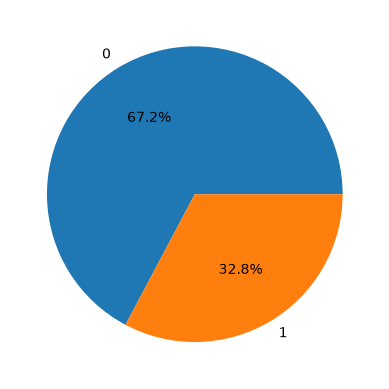

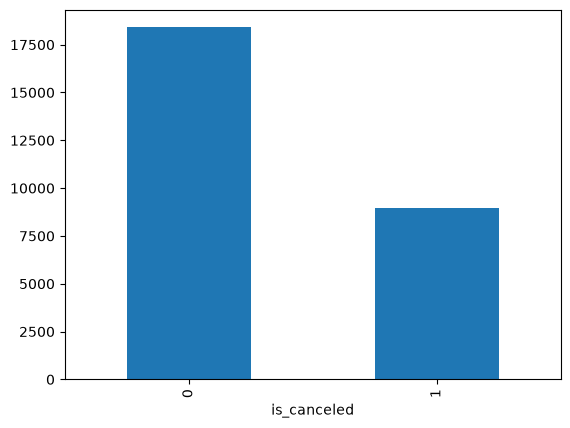

In [15]:
pie(train, column='is_canceled')
bar(train, column='is_canceled')

#### Insights

> - Kelas target tidak seimbang ringan: 32,8% pemesanan batal (1) dan 67,2% tidak batal (0).
- Model yang selalu menebak 0 sudah mendapat accuracy 67,2% tanpa pernah menebak pembatalan, sehingga macro F1 lebih cocok karena kedua kelas dihitung sama penting.

## Feature Analysis

In [16]:
num_col = ['days_before_arrival', 'nightly_rate_idr', 'weekend_nights', 'weekday_nights', 'special_requests',
           'num_adults', 'num_children', 'prior_completed_bookings']
cat_col = ['meal_package', 'room_category', 'booking_channel', 'needs_parking', 'is_returning_guest', 'arrival_month']

Statistik ringkas (describe)

In [17]:
train.describe().T

,count,mean,std,min,25%,50%,75%,max
num_adults,26564.0,1.845242e+00,0.517974,0.0,2.0,2.0,2.0,4.0
num_children,24338.0,1.173884e-01,0.425761,0.0,0.0,0.0,0.0,10.0
weekend_nights,27373.0,8.148541e-01,0.875146,0.0,0.0,1.0,2.0,7.0
weekday_nights,27373.0,2.206517e+00,1.421603,0.0,1.0,2.0,3.0,17.0
needs_parking,26291.0,3.020045e-02,0.171142,0.0,0.0,0.0,0.0,1.0
days_before_arrival,26250.0,8.537943e+01,85.969638,0.0,17.0,58.0,126.0,448.0
arrival_year,27373.0,2.023820e+03,0.384099,2023.0,2024.0,2024.0,2024.0,2024.0
arrival_month,27373.0,7.399664e+00,3.074788,1.0,5.0,8.0,10.0,12.0
arrival_day,27373.0,1.553754e+01,8.773321,1.0,8.0,16.0,23.0,31.0
is_returning_guest,27373.0,2.517079e-02,0.156646,0.0,0.0,0.0,0.0,1.0


`histogram` dan `boxplot` menggambar distribusi fitur numerik dalam grid tiga kolom.

- `columns` berisi satu nama kolom atau daftar kolom, misalnya `num_col`
- `by` berisi kolom pemisah kelompok, misalnya `Settings.TARGET`, atau `None`
- `bins` berisi jumlah bin histogram, dengan nilai bawaan `30`
- `data` berisi DataFrame selain `train`, dengan nilai bawaan `None`

In [18]:
def as_list(columns):
    return [columns] if isinstance(columns, str) else list(columns)

def make_axes(count, ncols=3):
    nrows = -(-count // ncols)
    figure, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.4 * nrows), squeeze=False)

    for axis in axes.flat[count:]:
        axis.axis('off')

    return axes.flat[:count]

def histogram(columns, by=None, bins=30, data=None):
    frame = train if data is None else data

    for axis, column in zip(make_axes(len(as_list(columns))), as_list(columns)):
        edges = np.histogram_bin_edges(frame[column].dropna(), bins=bins)

        if by is None:
            axis.hist(frame[column].dropna(), bins=edges)
        else:
            for label, group in frame.groupby(by):
                axis.hist(group[column].dropna(), bins=edges, alpha=0.5, label=str(label))

            axis.legend(title=by)

        axis.set_title(column)

    plt.tight_layout()
    plt.show()

def boxplot(columns, by=None, data=None):
    frame = train if data is None else data

    for axis, column in zip(make_axes(len(as_list(columns))), as_list(columns)):
        if by is None:
            axis.boxplot(frame[column].dropna())
            axis.set_xticks([])
        else:
            groups = list(frame.groupby(by)[column])
            axis.boxplot([values.dropna() for _, values in groups])
            axis.set_xticks(range(1, len(groups) + 1), [str(label) for label, _ in groups])

        axis.set_title(column)

    plt.tight_layout()
    plt.show()

Distribusi fitur numerik per kelas.

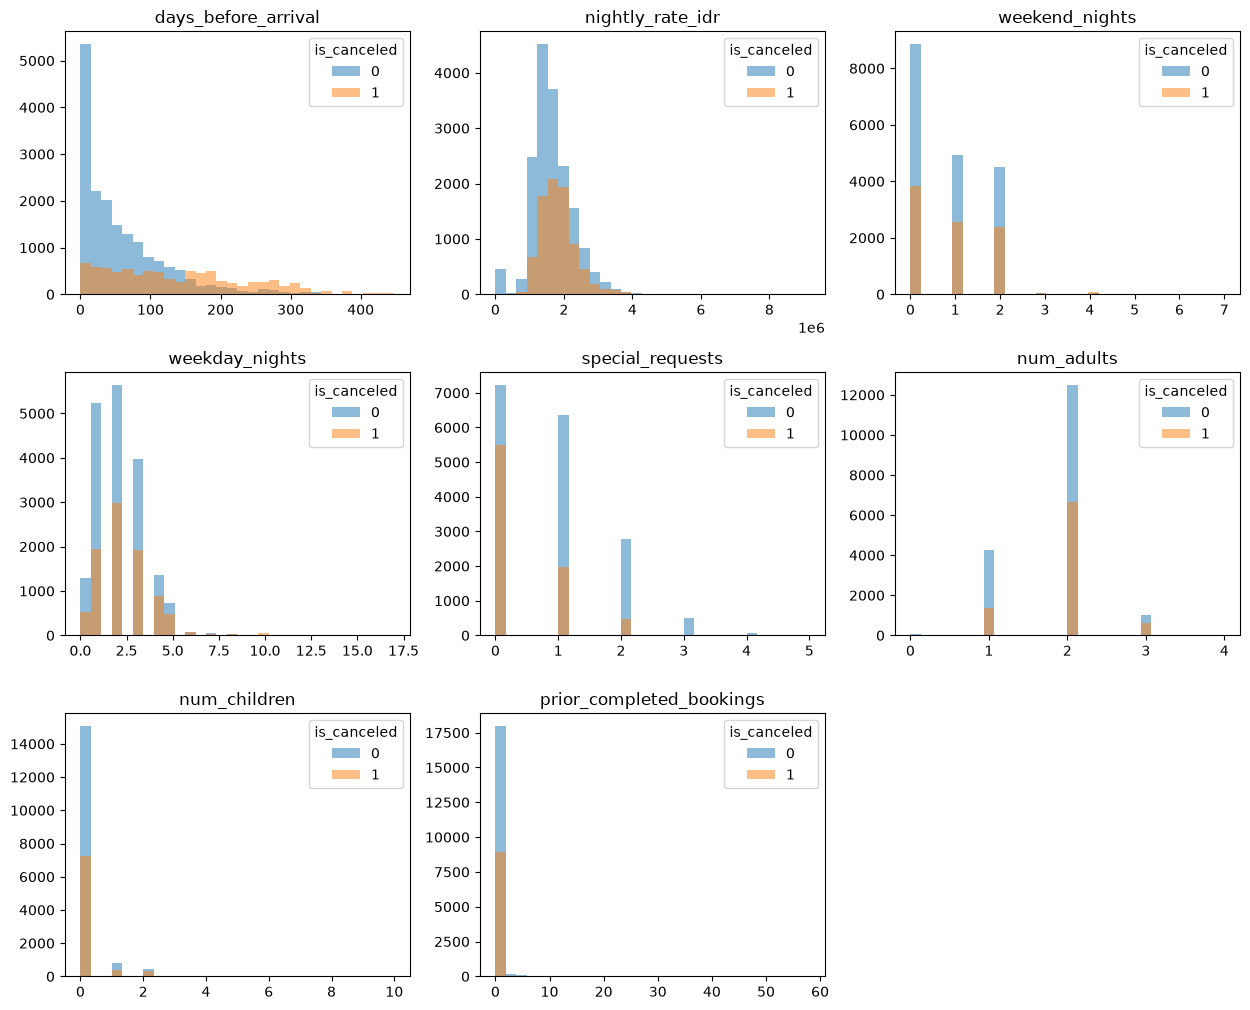

In [19]:
histogram(num_col, by=Settings.TARGET, bins=30, data=train)

Pengecekan outlier.

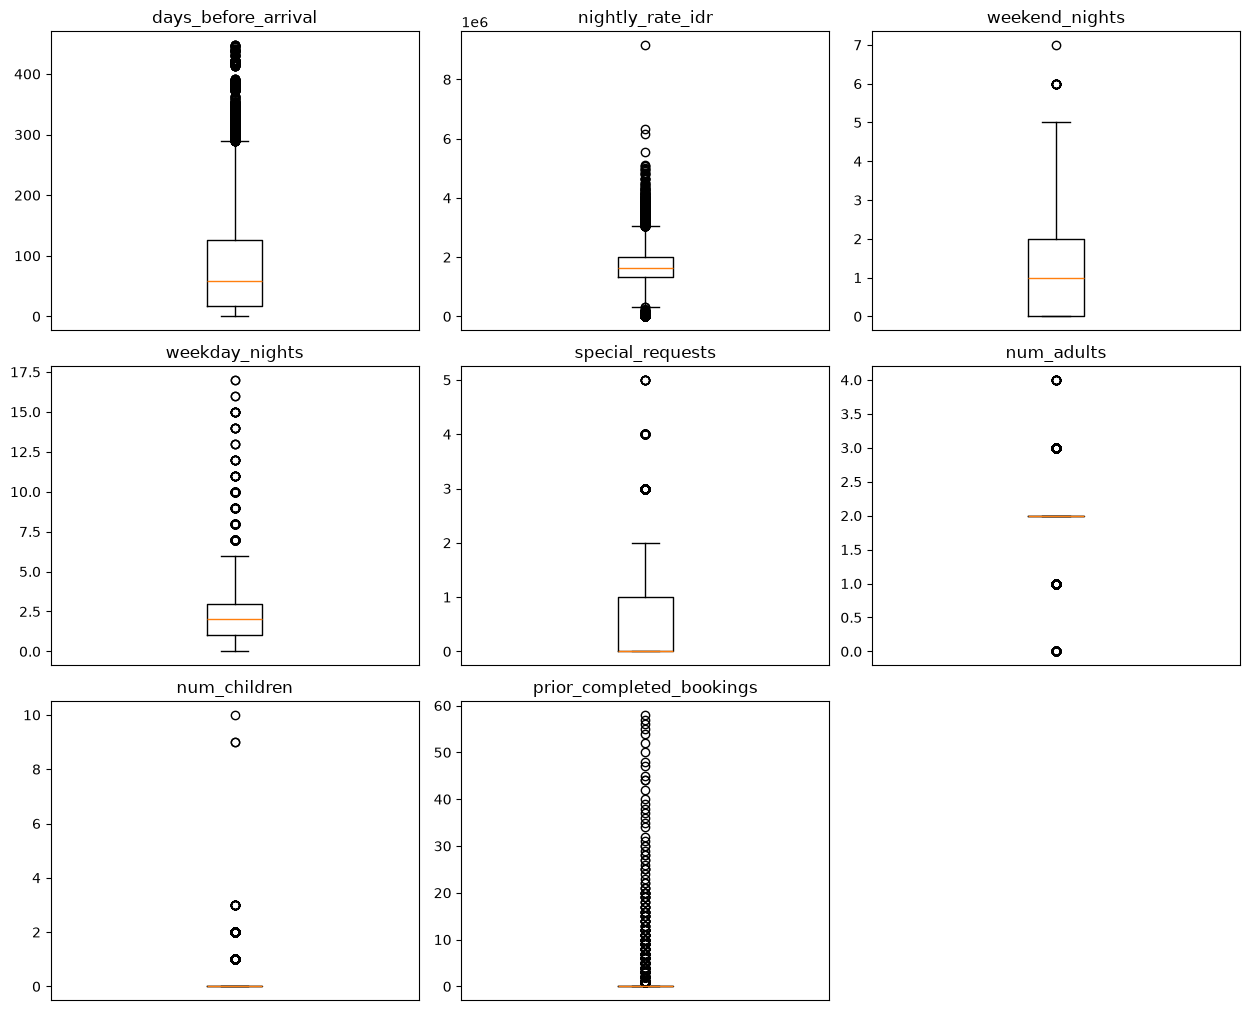

In [20]:
boxplot(num_col, by=None, data=train)

#### Insights

> - `days_before_arrival` miring ke kanan: median 58 hari, Q3 126 hari, maksimum 448 hari. Pada histogram, kelas batal jauh lebih banyak di lead time panjang.
- `nightly_rate_idr` juga miring ke kanan dengan banyak outlier atas (Q3 2.019.000, maksimum 9.165.000), dan ada 413 kamar gratis (harga 0) yang hampir tidak pernah batal (0,7%).
- `special_requests` berkisar 0 sampai 5, kelas batal terkumpul di 0.
- Fitur jumlah tamu dan malam bersifat diskrit dengan rentang sempit, outlier pada boxplot hanyalah nilai jarang seperti 10 anak atau 17 malam.

Hubungan fitur dengan `is_canceled`.

- `target_rate(df, columns)` menggambar rate `is_canceled` untuk setiap kategori dalam grid dua kolom
- `correlation(df)` menghitung korelasi fitur numerik dengan `is_canceled`, terurut dari nilai absolut terbesar

In [21]:
def target_rate(df, columns):
    for axis, column in zip(make_axes(len(as_list(columns)), ncols=2), as_list(columns)):
        df.groupby(column)[Settings.TARGET].mean().plot.bar(ax=axis)
        axis.set_title(column)
        axis.set_ylabel(f'rate {Settings.TARGET}')

    plt.tight_layout()
    plt.show()

def correlation(df):
    numbers = df.select_dtypes('number').drop(columns=[Settings.TARGET])
    values = numbers.corrwith(df[Settings.TARGET])

    return values.reindex(values.abs().sort_values(ascending=False).index)

Rate `is_canceled` untuk setiap kategori.

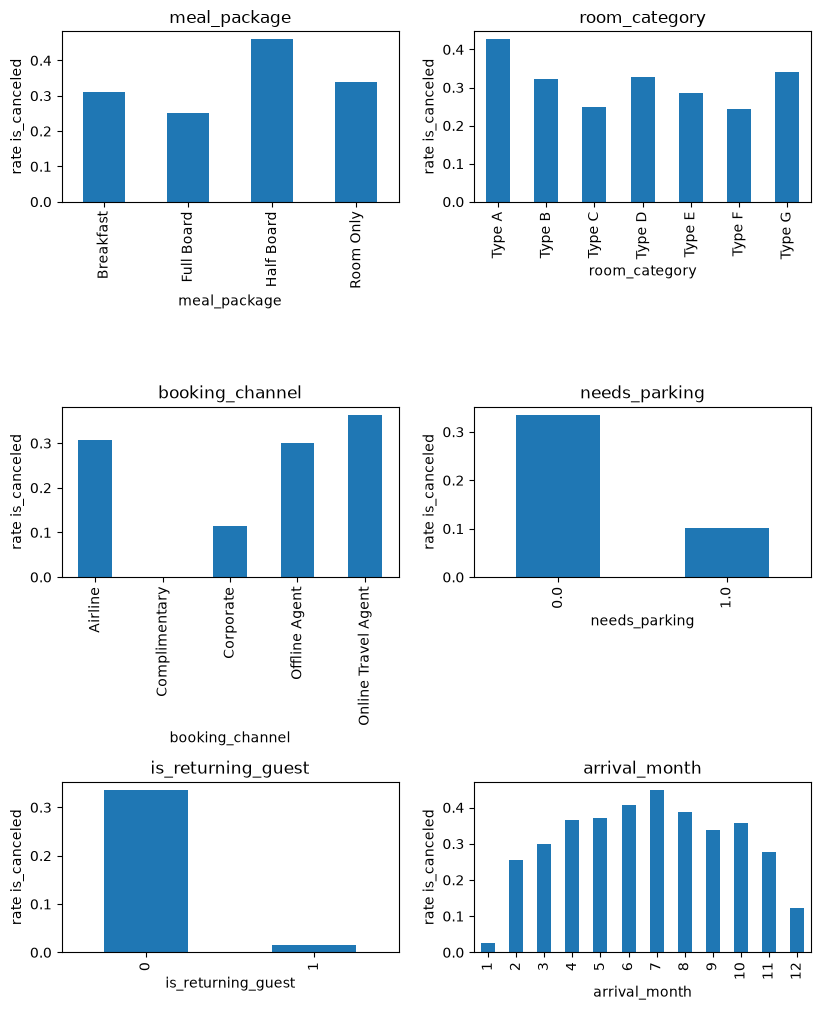

In [22]:
target_rate(train, cat_col)

Korelasi fitur numerik dengan `is_canceled`.

In [23]:
correlation(train)

days_before_arrival         0.440316
special_requests           -0.257996
arrival_year                0.179826
nightly_rate_idr            0.134092
is_returning_guest         -0.107207
weekday_nights              0.097226
num_adults                  0.088446
needs_parking              -0.085504
weekend_nights              0.060797
prior_completed_bookings   -0.058894
prior_cancellations        -0.035006
num_children                0.030856
arrival_day                 0.020005
arrival_month              -0.015912
dtype: float64

#### Insights

> - `days_before_arrival` memiliki korelasi terbesar (0,44). Rate batal naik dari 14,4% (lead time 30 hari atau kurang) ke 73,6% (lebih dari 180 hari).
- `special_requests` berkorelasi negatif (-0,26). Rate batal 43,2% tanpa permintaan, 23,8% dengan 1 permintaan, dan 0% untuk 3 permintaan atau lebih.
- `booking_channel` berpengaruh kuat: Online Travel Agent 36,4%, Offline Agent 30,2%, Corporate 11,5%, Complimentary 0%.
- Tamu yang butuh parkir (10,1%) dan tamu lama (1,5%) jarang batal.
- Rate batal bergantung musim: Januari 2,6% dan Desember 12,1%, sedangkan Juni sampai Agustus sekitar 40% sampai 45%. Karena itu fitur waktu kedatangan seperti `arrival_dayofyear` dan `arrival_index` dibentuk pada feature engineering.

---

# Data Cleaning and Preprocessing <a name="4"></a>

---

Data dibagi sebelum preprocessing. Setiap langkah di-fit hanya pada frame pertama (`X_train`), lalu diterapkan pada semua frame (`X_train`, `X_val`, `X_test`). Setiap fungsi menerima list `frames` dan mengembalikan list baru, sehingga langkah yang sama bisa diulang pada submisi final dengan seluruh data train.

## Data Split

Pembagian `train` menjadi `X_train` dan `X_val`.

- `X` berisi fitur `train` tanpa kolom `id` dan `is_canceled`
- `y` berisi kolom `is_canceled`
- `X_test` berisi fitur `test` tanpa kolom `id`

In [24]:
X = train.drop(columns=[Settings.ID_COLUMN, Settings.TARGET])
y = train[Settings.TARGET]

X_test = test.drop(columns=[Settings.ID_COLUMN])
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=Settings.TEST_SIZE, stratify=y, random_state=Settings.SEED
)

pd.Series({'X_train': len(X_train), 'X_val': len(X_val), 'X_test': len(X_test)})

X_train    21898
X_val       5475
X_test      6844
dtype: int64

## Duplicate

Baris duplikat persis (fitur dan target sama) pada `X_train` dihapus beserta `y_train`. Baris pada `X_val` dan `X_test` tidak dihapus.

`drop_duplicates_train` mengembalikan `X` dan `y` tanpa baris duplikat.

In [25]:
def drop_duplicates_train(X, y):
    keep = ~X.assign(**{Settings.TARGET: y}).duplicated()

    return X[keep], y[keep]

In [26]:
before = len(X_train)
X_train, y_train = drop_duplicates_train(X_train, y_train)
pd.Series({'sebelum': before, 'sesudah': len(X_train)})

sebelum    21898
sesudah    21858
dtype: int64

#### Keputusan

> Baris duplikat persis pada data latih dihapus.
- Baris identik tidak membawa informasi baru, tetapi membuat KNN menghitung tetangga yang sama berkali-kali.
- Hanya data latih yang dibersihkan. Data validasi dan test tetap utuh agar skor dan submisi mewakili data asli.

## Nilai Janggal

`mark_invalid_values` mengubah `num_adults = 0` menjadi missing value pada semua frame, sebelum fitur turunan dihitung.

In [27]:
def mark_invalid_values(frames):
    return [mark_invalid(frame) for frame in frames]

In [28]:
X_train, X_val, X_test = mark_invalid_values([X_train, X_val, X_test])
X_train['num_adults'].isna().sum()

np.int64(720)

#### Keputusan

> num_adults = 0 dianggap missing value.
- Pemesanan tanpa orang dewasa tidak masuk akal untuk penginapan, jadi nilai 0 lebih mungkin berarti tidak tercatat.
- Nilai ini kemudian diisi bersama missing value lain pada langkah imputasi.

## Feature Engineering

`engineer` menambah fitur turunan per baris, sehingga aman dipakai pada setiap frame secara terpisah.

- `total_nights`: `weekend_nights + weekday_nights`
- `total_guests`, `rate_per_guest`, `is_free`: jumlah tamu, harga per tamu, penanda kamar gratis
- `arrival_weekday`, `arrival_dayofyear`, `arrival_index`: hari dalam minggu, hari ke berapa dalam tahun, dan jumlah hari sejak 1 Januari 2023

Fitur turunan dihitung dari nilai asli sebelum imputasi, lalu missing pada fitur turunan ikut diisi pada langkah berikutnya.

In [29]:
def engineer(frames):
    return [add_features(frame) for frame in frames]

In [30]:
X_train, X_val, X_test = engineer([X_train, X_val, X_test])
X_train[['total_nights', 'arrival_dayofyear', 'arrival_index']].head()

,total_nights,arrival_dayofyear,arrival_index
3315,2,296.0,660.0
9891,3,308.0,672.0
11242,2,275.0,274.0
41,2,336.0,700.0
11576,3,130.0,494.0


#### Keputusan

> Fitur turunan dipakai.
- `arrival_index` dan `arrival_dayofyear` menjadi fitur penting untuk KNN, karena pembatalan berubah mengikuti waktu kedatangan.
- Model yang tidak membutuhkan fitur tertentu cukup tidak memilihnya (lihat KNN pada bagian 5).

## Missing Value

Missing value numerik diisi median, kategorikal diisi modus. Baris pada `X_test` tidak dapat dihapus.

`impute` melakukan fit pada frame pertama, lalu mengisi missing value pada semua frame.

- `columns` berisi satu kolom atau daftar kolom
- `strategy` bernilai `'mean'`, `'median'`, atau `'most_frequent'`

In [31]:
def impute(frames, columns, strategy='median'):
    columns = as_list(columns)
    frames = [frame.copy() for frame in frames]
    fit = frames[0][columns]

    if strategy == 'median':
        values = fit.median()
    elif strategy == 'mean':
        values = fit.mean()
    else:
        values = fit.mode().iloc[0]

    for frame in frames:
        frame[columns] = frame[columns].fillna(values)

    return frames

In [32]:
num_features = [c for c in X_train.columns if c not in CAT_COLS]

X_train, X_val, X_test = impute([X_train, X_val, X_test], num_features, 'median')
X_train, X_val, X_test = impute([X_train, X_val, X_test], CAT_COLS, 'most_frequent')
X_train.isna().sum().sum(), X_val.isna().sum().sum(), X_test.isna().sum().sum()

(np.int64(0), np.int64(0), np.int64(0))

#### Keputusan

> Numerik diisi median dan kategorikal diisi modus.
- Median tahan terhadap outlier, misalnya `days_before_arrival` dan `nightly_rate_idr` yang miring ke kanan.
- Alternatif yang sudah diuji pada KNN terbaik justru lebih buruk: median per grup (channel x bulan) -0,011, imputasi dengan KNN -0,006, dan konstanta di luar rentang -0,004 sampai -0,009.
- Dugaan kami, nilai median membuat baris missing berkumpul pada satu titik sehingga KNN memperlakukannya sebagai kelompok sendiri.

## Outlier

`cap_outliers` menghitung batas IQR dari frame pertama, lalu memotong nilai pada semua frame.

- `columns` berisi kolom numerik yang dipotong
- `factor` mengatur lebar batas IQR, dengan nilai bawaan `1.5`

In [33]:
def cap_outliers(frames, columns, factor=1.5):
    columns = as_list(columns)
    q1, q3 = frames[0][columns].quantile(0.25), frames[0][columns].quantile(0.75)
    lower, upper = q1 - factor * (q3 - q1), q3 + factor * (q3 - q1)

    return [frame.assign(**frame[columns].clip(lower, upper, axis=1)) for frame in frames]

In [34]:
# Langkah ini dilewati dengan justifikasi di bawah

#### Keputusan

> Outlier tidak dipotong.
- Nilai ekstrem seperti `days_before_arrival` di atas 400 hari justru informatif, karena pemesanan sangat jauh hari lebih sering batal.
- Scaling dengan standardisasi sudah cukup agar fitur besar tidak mendominasi jarak KNN.
- Pada eksperimen Decision Tree, capping IQR tidak memberi kenaikan skor.

## Encoding

`encode` membuat kolom one-hot dengan kategori dari frame pertama. Kategori yang tidak dikenal pada frame lain menjadi nol di semua kolomnya.

- `columns` berisi kolom kategorikal

In [35]:
def encode(frames, columns):
    columns = as_list(columns)
    levels = {c: sorted(frames[0][c].dropna().unique()) for c in columns}
    result = []

    for frame in frames:
        frame = frame.copy()
        for c in columns:
            for level in levels[c]:
                frame[f'{c}_{level}'] = (frame[c] == level).astype(float)
        result.append(frame.drop(columns=columns))

    return result

In [36]:
X_train, X_val, X_test = encode([X_train, X_val, X_test], CAT_COLS)
[c for c in X_train.columns if c.startswith('booking_channel')]

['booking_channel_Airline',
 'booking_channel_Complimentary',
 'booking_channel_Corporate',
 'booking_channel_Offline Agent',
 'booking_channel_Online Travel Agent']

#### Keputusan

> Ketiga kolom kategorikal di-encode one-hot.
- `meal_package`, `room_category`, dan `booking_channel` tidak punya urutan alami yang konsisten dengan rate pembatalan, sehingga ordinal encoding akan membuat jarak palsu.
- Pada KNN from scratch, kolom one-hot dikali 0,5. Dengan jarak Manhattan, dua kategori berbeda berjarak 0,5 + 0,5 = 1 dan kategori sama berjarak 0, sesuai jarak atribut simbolik pada materi KNN.

## Scaling

`scale` melakukan standardisasi `(x - mean) / std` dengan mean dan std dari frame pertama.

- `columns` berisi kolom numerik

In [37]:
def scale(frames, columns):
    columns = as_list(columns)
    mean, std = frames[0][columns].mean(), frames[0][columns].std().replace(0, 1)

    return [frame.assign(**((frame[columns] - mean) / std)) for frame in frames]

In [38]:
X_train, X_val, X_test = scale([X_train, X_val, X_test], num_features)
X_train[num_features].describe().loc[['mean', 'std']].round(3)

,num_adults,num_children,weekend_nights,weekday_nights,needs_parking,days_before_arrival,arrival_year,arrival_month,arrival_day,is_returning_guest,...,prior_completed_bookings,nightly_rate_idr,special_requests,total_nights,total_guests,is_free,rate_per_guest,arrival_weekday,arrival_dayofyear,arrival_index
mean,0.0,-0.0,-0.0,0.0,0.0,-0.0,0.0,0.0,-0.0,-0.0,...,0.0,-0.0,-0.0,-0.0,-0.0,-0.0,0.0,-0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


#### Keputusan

> Standardisasi diterapkan pada semua kolom numerik.
- KNN dan SVM menghitung jarak, sehingga tanpa scaling `nightly_rate_idr` yang bernilai jutaan mendominasi fitur lain.
- Logistic Regression membutuhkan scaling agar regularisasi adil antarfitur.
- Decision Tree dan Gaussian NB tidak terpengaruh scaling secara berarti.
- Kolom one-hot tidak di-scale karena nilainya sudah 0 dan 1.

## Ringkasan Preprocessing

`preprocess` merangkum semua langkah di atas dengan urutan yang sama, dipakai lagi pada submisi final.

In [39]:
def preprocess(frames):
    frames = engineer(mark_invalid_values(frames))
    numeric = [c for c in frames[0].columns if c not in CAT_COLS]
    frames = impute(frames, numeric, 'median')
    frames = impute(frames, CAT_COLS, 'most_frequent')
    frames = encode(frames, CAT_COLS)
    return scale(frames, numeric)

---

# Modeling and Validation <a name="5"></a>

---

Baseline kelima model, lalu tuning.

## Class Imbalance

`resample` menyeimbangkan kelas pada data latih dengan random undersampling atau oversampling. Resampling hanya diterapkan pada data latih.

- `method` bernilai `None`, `'undersample'`, atau `'oversample'`

In [40]:
def resample(X, y, method=None):
    if method is None:
        return X, y

    rng = np.random.default_rng(Settings.SEED)
    groups = [np.where(y.to_numpy() == c)[0] for c in (0, 1)]
    size = min(map(len, groups)) if method == 'undersample' else max(map(len, groups))
    index = np.concatenate([rng.choice(g, size, replace=len(g) < size) for g in groups])

    return X.iloc[index], y.iloc[index]

In [41]:
# Langkah ini dilewati dengan justifikasi di bawah

#### Keputusan

> Tidak dilakukan resampling (method=None).
- Rasio kelas sekitar 67:33 tergolong ringan.
- Resampling sebelum split membuat data validasi bocor ke data latih. Banyak notebook publik dataset asal kompetisi ini melaporkan akurasi 93% sampai 97% karena oversampling dilakukan sebelum split. Skor jujur model pohon tunggal hanya sekitar 87%.
- Ketidakseimbangan ditangani dengan memilih threshold prediksi KNN dari validasi, sehingga macro F1 tetap memberi bobot sama untuk kedua kelas.

## KNN

KNN from scratch (NumPy). Fit hanya menyimpan data, semua perhitungan terjadi saat prediksi.

- `k` jumlah tetangga, `p` jarak Minkowski (`1` Manhattan, `2` Euclidean)
- `vote` bernilai `'majority'` (materi) atau `'distance'`, yaitu suara tetangga dibobot `1 / jarak` (di luar materi)
- `features` daftar fitur yang dipakai, hasil forward selection pada eksperimen `knn_selection_distance`
- `weights` bobot jarak per fitur, kosong berarti semua bobot 1
- `threshold` batas probabilitas kelas 1, dipilih dari validasi out-of-fold (di luar materi)

**Distance-weighted voting (di luar materi).** Pada voting mayoritas, tetangga ke-1 dan ke-k bersuara sama. Di sini `P(batal) = Σ w_i × label_i / Σ w_i` dengan `w_i = 1 / (jarak_i + 1e-6)`, sehingga tetangga yang hampir identik dengan query lebih menentukan. Contoh k = 3, label (1, 0, 0), jarak (0,1; 1; 1): mayoritas memberi 1/3, distance voting memberi 10/12 = 0,83.

**Forward selection (materi Data Preparation, wrapper).** Mulai dari himpunan kosong, setiap langkah menambah satu fitur yang paling menaikkan macro F1 OOF, berhenti jika kenaikan di bawah 0,0005. Dari 32 kandidat terpilih 8 fitur. Prosesnya sekitar 30 menit sehingga hasilnya ditulis langsung di `KNN_FEATURES`.

In [42]:
# Jarak Minkowski pangkat p (tanpa akar) dari setiap query ke setiap data train.
def minkowski_power(Q, X, p):
    d = np.zeros((len(Q), len(X)), dtype=np.float32)
    for j in range(X.shape[1]):
        d += np.abs(Q[:, j, None] - X[None, :, j]) ** p
    return d


# Probabilitas kelas 1 dari label dan jarak k tetangga terdekat.
def vote_proba(dist, labels, vote):
    if vote == 'distance':
        w = 1.0 / (dist + 1e-6)
        return (w * labels).sum(1) / w.sum(1)
    return labels.mean(1)


class KNN:

    def __init__(self, k=19, p=1, vote='distance', features=None, weights=None, threshold=0.5, batch_size=500):
        self.k = k
        self.p = p
        self.vote = vote
        self.features = features
        self.weights = weights or {}
        self.threshold = threshold
        self.batch_size = batch_size

    # Ambil kolom fitur terpilih: numerik dulu, lalu one-hot dikali 0,5, kemudian kali bobot per fitur
    def _matrix(self, X):
        features = self.features or [c for c in X.columns]
        numeric = [f for f in features if f not in CAT_COLS]
        parts = [X[numeric].to_numpy()]
        blocks = {f: [i] for i, f in enumerate(numeric)}
        start = len(numeric)

        for f in [f for f in features if f in CAT_COLS]:
            onehot = [c for c in X.columns if c.startswith(f + '_')]
            parts.append(X[onehot].to_numpy() * 0.5)
            blocks[f] = list(range(start, start + len(onehot)))
            start += len(onehot)

        M = np.hstack(parts).astype(np.float32)
        for f, w in self.weights.items():
            M[:, blocks[f]] *= w
        return M

    # Lazy learner, cukup simpan data train
    def fit(self, X, y):
        self.X_ = self._matrix(X)
        self.y_ = np.asarray(y).astype(int)
        return self

    # Jarak dan indeks k tetangga terdekat, terurut dari yang terdekat
    def kneighbors(self, X):
        Q = self._matrix(X)
        all_dist, all_idx = [], []
        for s in range(0, len(Q), self.batch_size):
            d = minkowski_power(Q[s:s + self.batch_size], self.X_, self.p)
            idx = np.argpartition(d, self.k - 1, axis=1)[:, :self.k]
            order = np.argsort(np.take_along_axis(d, idx, axis=1), axis=1, kind='stable')
            idx = np.take_along_axis(idx, order, axis=1)
            all_idx.append(idx)
            all_dist.append(np.take_along_axis(d, idx, axis=1) ** (1 / self.p))
        return np.vstack(all_dist), np.vstack(all_idx)

    def predict_proba(self, X):
        dist, idx = self.kneighbors(X)
        return vote_proba(dist, self.y_[idx], self.vote)

    def predict(self, X):
        return (self.predict_proba(X) >= self.threshold).astype(int)

In [43]:
KNN_FEATURES = ['days_before_arrival', 'arrival_index', 'special_requests', 'nightly_rate_idr',
                'booking_channel', 'arrival_dayofyear', 'total_nights', 'needs_parking']

knn = KNN(k=3, p=2, vote='majority', features=KNN_FEATURES)
knn

## DTL

Decision Tree from scratch kelompok (bagian Kode Pendukung). Kriteria `gain_ratio` adalah C4.5 dari materi.

In [44]:
dtl = DecisionTree(criterion='gini', max_depth=None, min_samples_leaf=1)
dtl

## SVM

Support Vector Machine scikit-learn sebagai pembanding.

In [45]:
svc = SVC(gamma='scale', random_state=Settings.SEED)
svc

,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None


## Logistic Regression

Logistic Regression scikit-learn sebagai pembanding.

In [46]:
lr = LogisticRegression(C=1.0, solver='lbfgs', max_iter=2000)
lr

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

## Gaussian NB

Gaussian Naive Bayes scikit-learn sebagai pembanding.

In [47]:
gnb = GaussianNB()
gnb

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09


## Validation

Holdout melatih model pada `X_train` dan mengukurnya pada `X_val`. K-Fold hanya memakai `X_train`. Metrik yang dipakai adalah macro F1-score.

Kelima model dikumpulkan pada `models`.

In [48]:
models = {'knn': knn, 'dtl': dtl, 'svc': svc, 'lr': lr, 'gnb': gnb}
list(models)

['knn', 'dtl', 'svc', 'lr', 'gnb']

## Model Comparison

Perbandingan hasil validasi kelima model.

Holdout Method. `fit_predict` menyalin model, melatihnya, lalu memprediksi. `holdout` mengukur setiap model pada `X_val`.

- `models` berisi dictionary nama dan model, misalnya `models`
- `method` sama seperti pada `resample`

In [49]:
def fit_predict(model, X_fit, y_fit, X_eval, method=None):
    X_resampled, y_resampled = resample(X_fit, y_fit, method)

    return copy.deepcopy(model).fit(X_resampled, y_resampled).predict(X_eval)

def holdout(models, X_train, y_train, X_val, y_val, method=None):
    scores = {}

    for name, model in models.items():
        predicted = fit_predict(model, X_train, y_train, X_val, method)
        scores[name] = f1_score(y_val, predicted, average='macro')

    return pd.Series(scores, name='holdout').to_frame()

In [50]:
start = time.time()
holdout_table = holdout(models, X_train, y_train, X_val, y_val, method=None)
print(f'waktu {time.time() - start:.0f} detik')
holdout_table

waktu 14 detik


,holdout
knn,0.819095
dtl,0.807174
svc,0.802065
lr,0.759094
gnb,0.385699


K-Fold Cross Validation. `kfold` menghitung rata-rata dan simpangan baku skor K-Fold setiap model.

- `models` berisi dictionary nama dan model
- `X` dan `y` berisi data latih, misalnya `X_train` dan `y_train`
- `method` sama seperti pada `resample`

In [51]:
def kfold_scores(model, X, y, method=None):
    folds = StratifiedKFold(n_splits=Settings.N_FOLDS, shuffle=True, random_state=Settings.SEED)
    scores = []

    for fit_index, eval_index in folds.split(X, y):
        predicted = fit_predict(model, X.iloc[fit_index], y.iloc[fit_index], X.iloc[eval_index], method)
        scores.append(f1_score(y.iloc[eval_index], predicted, average='macro'))

    return np.array(scores)

def kfold(models, X, y, method=None):
    rows = {}

    for name, model in models.items():
        scores = kfold_scores(model, X, y, method)
        rows[name] = {'kfold_mean': scores.mean(), 'kfold_std': scores.std()}

    return pd.DataFrame(rows).T

In [52]:
start = time.time()
kfold_table = kfold(models, X_train, y_train)
print(f'waktu {time.time() - start:.0f} detik')

waktu 45 detik


Tabel perbandingan. `compare` menggabungkan tabel holdout dan K-Fold, lalu mengurutkannya dari `kfold_mean` tertinggi.

In [53]:
def compare(holdout_table, kfold_table):
    return holdout_table.join(kfold_table).sort_values('kfold_mean', ascending=False).round(4)

In [54]:
compare(holdout_table, kfold_table)

,holdout,kfold_mean,kfold_std
knn,0.8191,0.8140,0.0038
dtl,0.8072,0.8048,0.0028
svc,0.8021,0.7941,0.0023
lr,0.7591,0.7607,0.0017
gnb,0.3857,0.3694,0.0089


#### Insights

> - Dengan parameter default, KNN from scratch (8 fitur, k 3) mendapat skor k-fold tertinggi (0,8140), diikuti Decision Tree from scratch (0,8048), SVM (0,7941), Logistic Regression (0,7607), dan Gaussian NB (0,3694).
- Decision Tree tanpa batas kedalaman menghafal noise, sehingga skornya di bawah hasil tuning.
- Logistic Regression rendah karena pola data tidak linear, misalnya rate batal naik tajam setelah lead time 90 hari dan turun drastis pada bulan tertentu.
- Gaussian NB sangat rendah karena asumsi distribusi normal dan independen tidak cocok untuk kolom one-hot dan kolom diskrit, sehingga hampir semua baris ditebak batal (recall kelas 1 sekitar 0,96).
- Skor holdout dan k-fold setiap model berdekatan, sehingga data validasi cukup mewakili.

## Feature Importance

Fitur yang paling membantu Decision Tree dan Logistic Regression membedakan kedua kelas.

`importance` mengurutkan feature importance atau koefisien berdasarkan nilai absolutnya.

- `model` berupa Decision Tree atau Logistic Regression
- `X` dan `y` berisi data latih, misalnya `X_train` dan `y_train`

In [55]:
def importance(model, X, y, top=12):
    fitted = copy.deepcopy(model).fit(X, y)
    values = fitted.feature_importances_ if hasattr(fitted, 'feature_importances_') else fitted.coef_[0]
    ranked = pd.Series(values, index=X.columns)

    return ranked.reindex(ranked.abs().sort_values(ascending=False).index).head(top).round(4)

Decision Tree (dengan batas min gain agar tidak menghafal noise).

In [56]:
importance(DecisionTree(criterion='gain_ratio', max_depth=30, min_samples_leaf=5, min_impurity_decrease=2e-4), X_train, y_train)

days_before_arrival                    0.3482
special_requests                       0.1632
arrival_dayofyear                      0.1008
nightly_rate_idr                       0.1003
booking_channel_Online Travel Agent    0.0711
arrival_index                          0.0410
weekday_nights                         0.0214
rate_per_guest                         0.0213
weekend_nights                         0.0164
num_adults                             0.0149
prior_completed_bookings               0.0135
total_nights                           0.0129
dtype: float64

Logistic Regression.

In [57]:
importance(lr, X_train, y_train)

booking_channel_Complimentary         -1.9237
days_before_arrival                    1.2705
special_requests                      -1.1235
booking_channel_Airline                0.9628
booking_channel_Online Travel Agent    0.9023
booking_channel_Offline Agent         -0.8000
room_category_Type F                  -0.6490
meal_package_Breakfast                -0.5506
nightly_rate_idr                       0.5347
room_category_Type B                   0.3752
is_returning_guest                    -0.3513
meal_package_Room Only                -0.3245
dtype: float64

#### Insights

> - Pada Decision Tree, fitur terpenting adalah `days_before_arrival` (0,35), diikuti `special_requests` (0,16), `arrival_dayofyear` (0,10), `nightly_rate_idr` (0,10), dan `booking_channel` Online Travel Agent (0,07).
- Pada Logistic Regression, koefisien terbesar dimiliki `booking_channel` Complimentary (-1,92), `days_before_arrival` (1,27), dan `special_requests` (-1,12).
- Kedua model sepakat dengan EDA dan dengan hasil forward selection KNN: lead time, permintaan khusus, waktu kedatangan, harga, dan channel adalah fitur utama.

## Hyperparameter Tuning

`tune` mencoba setiap kombinasi pada `grid` dengan K-Fold dan mengurutkannya dari skor tertinggi.

- `grid` berupa dictionary nama parameter dan daftar nilainya, misalnya `{'k': [15, 19]}`
- `X`, `y`, dan `method` sama seperti pada `kfold`

In [58]:
def tune(model, grid, X, y, method=None):
    rows = []

    for params in ParameterGrid(grid):
        candidate = copy.deepcopy(model)
        for name, value in params.items():
            setattr(candidate, name, value)
        scores = kfold_scores(candidate, X, y, method)
        rows.append({**params, 'kfold_mean': scores.mean(), 'kfold_std': scores.std()})

    return pd.DataFrame(rows).sort_values('kfold_mean', ascending=False, ignore_index=True).round(4)

KNN. Fitur sudah dipilih dengan forward selection, di sini dicoba jarak, cara voting, k, dan threshold.

In [59]:
start = time.time()
knn_grid = tune(knn, {'p': [1, 2], 'vote': ['majority', 'distance'], 'k': [11, 19, 25], 'threshold': [0.5]}, X_train, y_train)
print(f'waktu {time.time() - start:.0f} detik')
knn_grid.head(6)

waktu 127 detik


,k,p,threshold,vote,kfold_mean,kfold_std
0,19,1,0.5,distance,0.8369,0.0048
1,11,1,0.5,distance,0.8351,0.0066
2,25,1,0.5,distance,0.8349,0.0053
3,19,2,0.5,distance,0.8310,0.0062
4,11,2,0.5,distance,0.8303,0.0051
5,25,2,0.5,distance,0.8292,0.0059


In [60]:
tune(knn, {'p': [1], 'vote': ['distance'], 'k': [19], 'threshold': [0.43, 0.45, 0.47, 0.49, 0.51]}, X_train, y_train)

,k,p,threshold,vote,kfold_mean,kfold_std
0,19,1,0.47,distance,0.8378,0.0053
1,19,1,0.49,distance,0.8376,0.0052
2,19,1,0.51,distance,0.8362,0.0047
3,19,1,0.45,distance,0.8360,0.0055
4,19,1,0.43,distance,0.8340,0.0064


Decision Tree, dengan kriteria dan batas min gain (pre-pruning).

In [61]:
start = time.time()
dtl_grid = tune(dtl, {'criterion': ['gini', 'gain_ratio'], 'max_depth': [30], 'min_samples_leaf': [5],
                      'min_impurity_decrease': [1e-4, 2e-4, 4e-4]}, X_train, y_train)
print(f'waktu {time.time() - start:.0f} detik')
dtl_grid

waktu 18 detik


,criterion,max_depth,min_impurity_decrease,min_samples_leaf,kfold_mean,kfold_std
0,gain_ratio,30,0.0002,5,0.8318,0.0033
1,gini,30,0.0002,5,0.8309,0.0036
2,gain_ratio,30,0.0004,5,0.8292,0.0027
3,gain_ratio,30,0.0001,5,0.8283,0.0025
4,gini,30,0.0004,5,0.8260,0.0054
5,gini,30,0.0001,5,0.8256,0.0037


SVM dengan kernel rbf dan beberapa nilai `C`.

In [62]:
start = time.time()
svc_grid = tune(svc, {'kernel': ['rbf'], 'C': [1, 3, 10]}, X_train, y_train)
print(f'waktu {time.time() - start:.0f} detik')
svc_grid

waktu 72 detik


,C,kernel,kfold_mean,kfold_std
0,10,rbf,0.8141,0.0018
1,3,rbf,0.8051,0.0007
2,1,rbf,0.7941,0.0023


Logistic Regression dengan beberapa nilai `C`.

In [63]:
lr_grid = tune(lr, {'C': [0.01, 0.1, 1, 10]}, X_train, y_train)
lr_grid

,C,kfold_mean,kfold_std
0,10.00,0.7610,0.0019
1,1.00,0.7607,0.0017
2,0.10,0.7604,0.0019
3,0.01,0.7558,0.0039


Gaussian NB dengan `var_smoothing`.

In [64]:
gnb_grid = tune(gnb, {'var_smoothing': [1e-9, 1e-6, 1e-3, 1e-1]}, X_train, y_train)
gnb_grid

,var_smoothing,kfold_mean,kfold_std
0,0.100,0.4709,0.0112
1,0.001,0.3957,0.0115
2,0.000,0.3811,0.0049
3,0.000,0.3694,0.0089


Model hasil tuning pada `tuned_models`. SVM, Logistic Regression, dan Gaussian NB mengambil baris teratas tabel tuning. KNN memakai konfigurasi submisi terbaik (`knn_selection_distance`): k 19, Manhattan, distance voting, threshold 0,47 dari OOF seluruh train. Decision Tree memakai konfigurasi `dt_gain_ratio`.

In [65]:
SVC_C, LR_C, GNB_VS = svc_grid.loc[0, 'C'], lr_grid.loc[0, 'C'], gnb_grid.loc[0, 'var_smoothing']

knn_tuned = KNN(k=19, p=1, vote='distance', features=KNN_FEATURES, threshold=0.47)
dtl_tuned = DecisionTree(criterion='gain_ratio', max_depth=30, min_samples_leaf=5, min_impurity_decrease=2e-4)
svc_tuned = SVC(kernel='rbf', C=SVC_C, gamma='scale', random_state=Settings.SEED)
lr_tuned = LogisticRegression(C=LR_C, solver='lbfgs', max_iter=2000)
gnb_tuned = GaussianNB(var_smoothing=GNB_VS)

tuned_models = {'knn': knn_tuned, 'dtl': dtl_tuned, 'svc': svc_tuned, 'lr': lr_tuned, 'gnb': gnb_tuned}

Perbandingan model hasil tuning.

In [66]:
start = time.time()
tuned_holdout = holdout(tuned_models, X_train, y_train, X_val, y_val, method=None)
tuned_kfold = kfold(tuned_models, X_train, y_train, method=None)
print(f'waktu {time.time() - start:.0f} detik')
compare(tuned_holdout, tuned_kfold)

waktu 64 detik


,holdout,kfold_mean,kfold_std
knn,0.8469,0.8378,0.0053
dtl,0.8363,0.8318,0.0033
svc,0.8171,0.8141,0.0018
lr,0.7590,0.7610,0.0019
gnb,0.4613,0.4709,0.0112


#### Insights

> - Setelah tuning, KNN from scratch tetap terbaik dengan k-fold 0,8378 dan holdout 0,8469, naik dari 0,8140. Kenaikan terbesar datang dari Manhattan dan distance voting (k 19), lalu threshold 0,47.
- Decision Tree from scratch naik dari 0,8048 menjadi 0,8318 dengan gain ratio dan batas min gain 2e-4.
- SVM naik dari 0,7941 menjadi 0,8141 dengan `C` 10. Logistic Regression hampir tidak berubah (0,7610), karena keterbatasannya ada pada bentuk model linear.
- Gaussian NB naik ke 0,4709 dengan `var_smoothing` 0,1, tetapi tetap jauh di bawah model lain.
- Skor KNN di sini (0,8378) sedikit di bawah OOF eksperimen (0,8411) karena di sini hanya memakai 80% data train.

---

# Error Analysis <a name="6"></a>

---

Analisis kesalahan prediksi pada `X_val`.

## Confusion Matrix

Confusion matrix serta precision dan recall kelima model.

`confusion` menggambar confusion matrix setiap model dalam satu baris, sedangkan `report` menampilkan precision, recall, dan F1-score setiap model.

- `models` berisi dictionary model, misalnya `tuned_models`
- `method` sama seperti pada `resample`

In [67]:
def confusion(models, X_train, y_train, X_val, y_val, method=None):
    figure, axes = plt.subplots(1, len(models), figsize=(4 * len(models), 3.6), squeeze=False)

    for axis, (name, model) in zip(axes.flat, models.items()):
        predicted = fit_predict(model, X_train, y_train, X_val, method)
        ConfusionMatrixDisplay.from_predictions(y_val, predicted, ax=axis, colorbar=False)
        axis.set_title(name)

    plt.tight_layout()
    plt.show()

def report(models, X_train, y_train, X_val, y_val, method=None):
    tables = {}

    for name, model in models.items():
        predicted = fit_predict(model, X_train, y_train, X_val, method)
        tables[name] = pd.DataFrame(classification_report(y_val, predicted, output_dict=True)).T

    return pd.concat(tables).round(3)

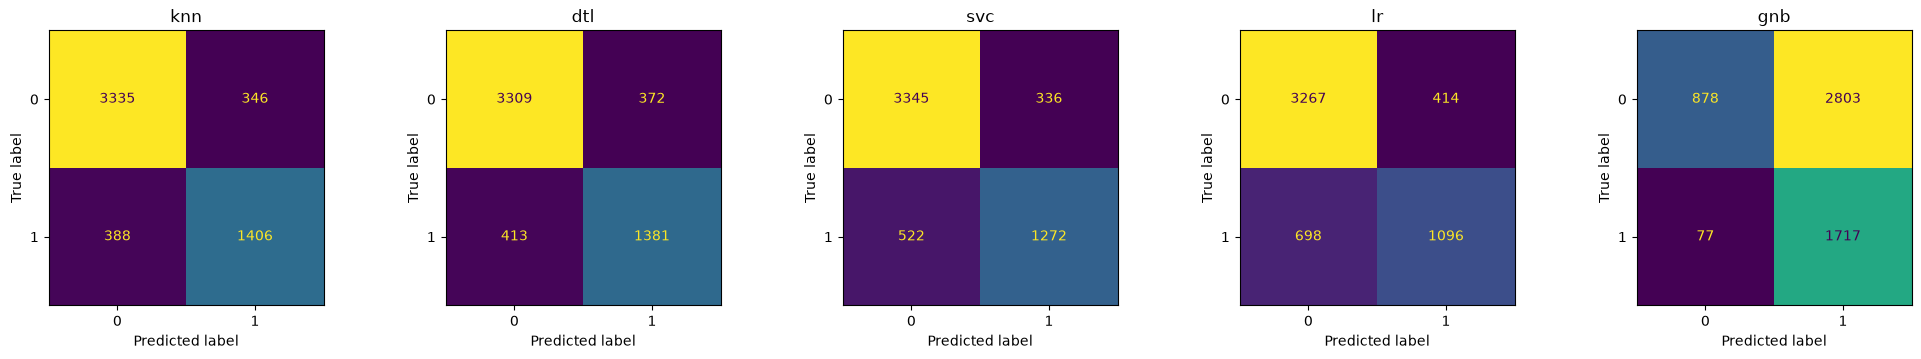

In [68]:
confusion(tuned_models, X_train, y_train, X_val, y_val, method=None)

Precision dan recall kelima model.

In [69]:
report(tuned_models, X_train, y_train, X_val, y_val, method=None)

precision  recall  f1-score   support
knn 0                 0.896   0.906     0.901  3681.000
    1                 0.803   0.784     0.793  1794.000
    accuracy          0.866   0.866     0.866     0.866
    macro avg         0.849   0.845     0.847  5475.000
    weighted avg      0.865   0.866     0.866  5475.000
dtl 0                 0.889   0.899     0.894  3681.000
    1                 0.788   0.770     0.779  1794.000
    accuracy          0.857   0.857     0.857     0.857
    macro avg         0.838   0.834     0.836  5475.000
    weighted avg      0.856   0.857     0.856  5475.000
svc 0                 0.865   0.909     0.886  3681.000
    1                 0.791   0.709     0.748  1794.000
    accuracy          0.843   0.843     0.843     0.843
    macro avg         0.828   0.809     0.817  5475.000
    weighted avg      0.841   0.843     0.841  5475.000
lr  0                 0.824   0.888     0.855  3681.000
    1                 0.726   0.611     0.663  1794.000
    accuracy          0.797   0.797     0.797     0.797
    macro avg         0.775   0.749     0.759  5475.000
    weighted avg      0.792   0.797     0.792  5475.000
gnb 0                 0.919   0.239     0.379  3681.000
    1                 0.380   0.957     0.544  1794.000
    accuracy          0.474   0.474     0.474     0.474
    macro avg         0.650   0.598     0.461  5475.000
    weighted avg      0.743   0.474     0.433  5475.000

#### Insights

> - KNN memiliki kesalahan paling sedikit (accuracy 0,866) dengan macro F1 0,847 pada data validasi.
- Recall kelas batal KNN 0,784, lebih tinggi dari Decision Tree (0,770), SVM (0,709), dan Logistic Regression (0,611).
- SVM dan Logistic Regression cenderung menebak tidak batal: recall kelas 0 tinggi (0,909 dan 0,888) tetapi banyak pembatalan terlewat.
- Gaussian NB kebalikannya: recall kelas 1 0,957 tetapi recall kelas 0 hanya 0,239.

## Misclassified Patterns

Baris asli `train` yang salah diprediksi oleh model terbaik.

`misclassified` mengembalikan baris `train` yang salah diprediksi beserta kolom `predicted`. `error_by` menghitung error rate per nilai satu kolom asli.

- `model` berisi model terbaik
- `column` nama kolom pada `train`, `bins` jumlah kuantil untuk kolom numerik

In [70]:
def misclassified(model, X_train, y_train, X_val, y_val, method=None):
    predicted = pd.Series(fit_predict(model, X_train, y_train, X_val, method), index=X_val.index)
    wrong = predicted[predicted != y_val]

    return train.loc[wrong.index].assign(predicted=wrong)

def error_by(wrong, column, bins=None):
    values = train.loc[X_val.index, column]
    values = values if bins is None else pd.qcut(values, bins, duplicates='drop')
    frame = pd.DataFrame({column: values, 'error': X_val.index.isin(wrong.index)})

    return frame.groupby(column, observed=True, dropna=False)['error'].agg(['mean', 'size']).round(3)

In [71]:
wrong = misclassified(knn_tuned, X_train, y_train, X_val, y_val, method=None)
print(len(wrong), 'dari', len(X_val), 'data validasi salah diprediksi')
wrong.head()

734 dari 5475 data validasi salah diprediksi


,id,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled,predicted
7924,9cb65da6,3.0,0.0,1,1,Breakfast,0.0,Type G,25.0,2024,6,17,Online Travel Agent,0,0,0,2892000.0,1.0,0,1
17141,ea3fcae4,2.0,0.0,2,0,Breakfast,0.0,Type D,246.0,2024,6,18,Online Travel Agent,0,0,0,1589000.0,1.0,0,1
5895,da7b2b94,2.0,0.0,0,3,Breakfast,0.0,Type G,28.0,2024,11,16,Online Travel Agent,0,0,0,1480000.0,NaN,0,1
1286,eeb67527,2.0,0.0,2,5,Breakfast,0.0,Type D,8.0,2023,8,27,Online Travel Agent,0,0,0,1378000.0,1.0,1,0
16320,23a66a27,2.0,2.0,2,2,Breakfast,0.0,Type A,75.0,2024,10,27,Online Travel Agent,0,0,0,2619000.0,1.0,1,0


In [72]:
error_by(wrong, 'booking_channel')

,mean,size
booking_channel,,
Airline,0.250,16
Complimentary,0.017,58
Corporate,0.081,309
Offline Agent,0.079,1573
Online Travel Agent,0.165,3519


In [73]:
error_by(wrong, 'days_before_arrival', bins=5)

,mean,size
days_before_arrival,,
"(-0.001, 11.0]",0.095,1051
"(11.0, 40.2]",0.134,1041
"(40.2, 81.0]",0.162,1065
"(81.0, 154.0]",0.178,1037
"(154.0, 448.0]",0.082,1035
NaN,0.215,246


In [74]:
error_by(wrong, 'special_requests')

,mean,size
special_requests,,
0.0,0.149,2579
1.0,0.131,1662
2.0,0.079,642
3.0,0.000,92
4.0,0.000,11
5.0,0.000,4
NaN,0.165,485


#### Insights

> - KNN salah memprediksi 734 dari 5.475 data validasi (13,4%).
- Error tertinggi ada pada baris dengan `days_before_arrival` kosong (21,5%). Median mengisi nilai tengah padahal fitur ini paling penting, sehingga tetangganya kurang mirip.
- Lead time 81 sampai 154 hari juga sulit (17,8%), karena rate batal pada rentang ini mendekati 50:50.
- Online Travel Agent (16,5%) lebih sulit dibanding Offline Agent (7,9%) dan Corporate (8,1%).
- Tamu dengan 3 permintaan khusus atau lebih tidak pernah salah ditebak, karena mereka tidak pernah membatalkan.

## Proposed Improvements

Usulan perbaikan berdasarkan hasil analisis.

- Memberi bobot per fitur pada jarak KNN. Pada eksperimen `knn_feature_weight`, bobot `days_before_arrival` 1,5 dan `total_nights` 0,5 menaikkan skor di 5 dari 5 pembagian fold (+0,0026), tetapi skor public turun tipis (0,85469 vs 0,85505), sehingga belum dipakai sebagai submisi terbaik.
- Menangani missing `days_before_arrival` dengan cara lain. Imputasi median per grup, imputasi dengan KNN, dan konstanta sudah dicoba dan semuanya lebih buruk, sehingga perlu pendekatan lain, misalnya menghitung jarak hanya dari fitur yang tidak kosong.
- Memfokuskan analisis pada Online Travel Agent dan lead time 80 sampai 150 hari, wilayah dengan error terbesar.

---

# Submission <a name="7"></a>

---

Submisi final yang dapat dihasilkan kembali dari notebook ini.

## Submit

Model final dilatih ulang dengan seluruh data train. Duplikat dibuang dengan `clean_train`, preprocessing di-fit ulang pada seluruh train dengan `preprocess`, lalu diterapkan ke test.

`submit` melatih model, memprediksi `X_test`, dan menyimpan file submisi.

- `X` dan `y` berisi data latih final hasil preprocessing
- `X_test` berisi fitur test hasil preprocessing

In [75]:
def submit(model, X, y, X_test, method=None):
    predictions = fit_predict(model, X, y, X_test, method)
    result = pd.DataFrame({Settings.ID_COLUMN: test[Settings.ID_COLUMN], Settings.TARGET: predictions})
    result.to_csv(Settings.SUB_PATH, index=False)
    print(f'{len(result)} rows written to {Settings.SUB_PATH}')

    return result

#### Pertanyaan

> Apakah model final perlu dilatih ulang dengan seluruh data train? Bagaimana jika tidak?

> Ya, perlu.
- Setelah parameter dipilih, `X_val` tidak lagi dibutuhkan untuk evaluasi sehingga dapat ditambahkan sebagai data latih.
- KNN menebak dari tetangga yang tersimpan, jadi data latih yang lebih banyak berarti tetangga yang lebih mirip untuk setiap baris test.
- Preprocessing juga di-fit ulang pada seluruh train agar median, mean, dan std mewakili semua data.

Submisi final.

In [76]:
full = clean_train(train)
X_full, X_test_final = preprocess([full.drop(columns=[Settings.ID_COLUMN, Settings.TARGET]),
                                   test.drop(columns=[Settings.ID_COLUMN])])
y_full = full[Settings.TARGET]

submission = submit(knn_tuned, X_full, y_full, X_test_final, method=None)
submission[Settings.TARGET].value_counts(normalize=True).round(4)

6844 rows written to /home/reinsensilitonga/Documents/kaggle_competitions/IF3170_G17_DerbyCounty/output/submissions/submission_knn_best_all_models.csv


is_canceled
0    0.6943
1    0.3057
Name: proportion, dtype: float64